In [18]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.stats import beta

import seaborn as sns
import matplotlib.pyplot as plt

# goal 1: Win prob and leverage model
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, log_loss

# goal 2: rotation optimization model and statistical analysis
import statsmodels.api as sm
import statsmodels.formula.api as smf

#goal 3: serve strategy
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams['figure.figsize'] = (12, 6)

In [6]:
# load the dataset
df = pd.read_csv('C:\\Users\\Thitirat\\OneDrive\\Documents\\volleyball_analysis_extended\\cleaned_volleyball_season_data-v2.csv')

# print overview
print(f"Dataset Overview:{df.shape[0]} rows, {df.shape[1]} columns\n")
print("Rallies by Season: ")
print(df['Season'].value_counts())

# preview the first few rows of the dataset
df.head()

Dataset Overview:5755 rows, 30 columns

Rallies by Season: 
Season
24-25    3302
25-26    2453
Name: count, dtype: int64


,Season,Set,Opponent,Timestamp,Rally,Rotation,Stage,Player,Action Type,Action,...,Timeout_By,Score_Clean,Us_Score,Them_Score,Score_Normalized,Acting_Team,Point_Winner,Point_Source,Recomputed_Runs_Before,Recomputed_Runs
0,24-25,1,ACG,2:31:57 PM,1.0,2.0,receive,(Opponent),earned,Ace,...,NaN,0 - 1,0.0,1.0,0 - 1,them,them,Opponent Earned,0,1
1,24-25,1,ACG,2:32:17 PM,2.0,2.0,receive,(Opponent),earned,Ace,...,NaN,0 - 2,0.0,2.0,0 - 2,them,them,Opponent Earned,1,2
2,24-25,1,ACG,2:32:53 PM,3.0,2.0,receive,(Opponent),errors,Free Ball Receive,...,NaN,1 - 2,1.0,2.0,1 - 2,them,us,Opponent Error,0,1
3,24-25,1,ACG,2:33:16 PM,4.0,3.0,serve,#1 Hrishika,earned,Spike,...,NaN,2 - 2,2.0,2.0,2 - 2,us,us,Our Earned,1,2
4,24-25,1,ACG,2:33:44 PM,5.0,3.0,serve,#9 Anne,errors,Serve,...,NaN,2 - 3,2.0,3.0,2 - 3,us,them,Our Error,0,1


# GOAL 1: Win probability & leverage model

In [11]:
# Determine set winner for every set in the dataset
# Team with higher score at the final rally of the set is the winner

final_rallies = df.groupby(['Season', 'Opponent', 'Set']).tail(1).copy()
final_rallies['Set_Won'] = (final_rallies['Us_Score'] > final_rallies['Them_Score']).astype(int)

# Merge Set_Won back to the original dataframe
df = df.merge(final_rallies[['Season', 'Opponent', 'Set', 'Set_Won']], on=['Season', 'Opponent', 'Set'], how='left')

# Create pre-rally state features
df['Score_Diff'] = df['Us_Score'] - df['Them_Score']
df['Is_Serving'] = (df['Stage'] == 'Serve').astype(int)
df['Point_Won'] = (df['Point_Winner'] == 'us').astype(int)

# State features list
features = [
    'Score_Diff',
    'Is_Serving',
    'Us_Score',
    'Them_Score',
    'Set',
    'Rotation',
    'Recomputed_Runs_Before'
]

# filter clean dataset for modeling
model_df = df.dropna(subset=features + ['Set_Won', 'Point_Won']).copy()

print(f"State Dataset Prepared: {len(model_df)} rally records")

print(f"Overall Set Win Rate: {model_df['Set_Won'].mean():.2%}")

print(f"Overall Rally Win Rate: {model_df['Point_Won'].mean():.2%}")

model_df[features].head()


State Dataset Prepared: 5693 rally records
Overall Set Win Rate: 59.02%
Overall Rally Win Rate: 52.64%


,Score_Diff,Is_Serving,Us_Score,Them_Score,Set,Rotation,Recomputed_Runs_Before
0,-1.0,0,0.0,1.0,1,2.0,0
1,-2.0,0,0.0,2.0,1,2.0,1
2,-1.0,0,1.0,2.0,1,2.0,0
3,0.0,0,2.0,2.0,1,3.0,1
4,-1.0,0,2.0,3.0,1,3.0,0


In [13]:
## Model training

# separate features matrics
X = model_df[features]
y_rally = model_df['Point_Won']
y_set = model_df['Set_Won']

# Model P(win next rally) using logistic regression
log_reg_rally = LogisticRegression(max_iter=1000)
log_reg_rally.fit(X, y_rally)
model_df['P_Win_Rally'] = log_reg_rally.predict_proba(X)[:, 1]

# Model P(win set) using xgboost classifier
xgb_set = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    random_state=42
)
xgb_set.fit(X, y_set)
model_df['P_Win_Set_Current'] = xgb_set.predict_proba(X)[:, 1]

# perfromance evaluation
rally_auc = roc_auc_score(y_rally,
                          model_df['P_Win_Rally'])
set_auc = roc_auc_score(y_set,
                        model_df['P_Win_Set_Current'])

print("===Model Performance===")
print(f"Rally Win Probability Model AUC: {rally_auc:.4f}")
print(f"Set Win Probability Model AUC: {set_auc:.4f}")

# feauture importance for P(win set)
importances = pd.Series(xgb_set.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature Importance for Set Win Probability Model:")
print(importances.round(4))

===Model Performance===
Rally Win Probability Model AUC: 0.6572
Set Win Probability Model AUC: 0.8225

Feature Importance for Set Win Probability Model:
Score_Diff                0.7172
Rotation                  0.0795
Set                       0.0783
Them_Score                0.0508
Us_Score                  0.0440
Recomputed_Runs_Before    0.0302
Is_Serving                0.0000
dtype: float32


=== Leverage Index Analysis===
Average Rally Leverage Index: 0.1008
Average Leverage Index at Timeout Calls: 0.1011


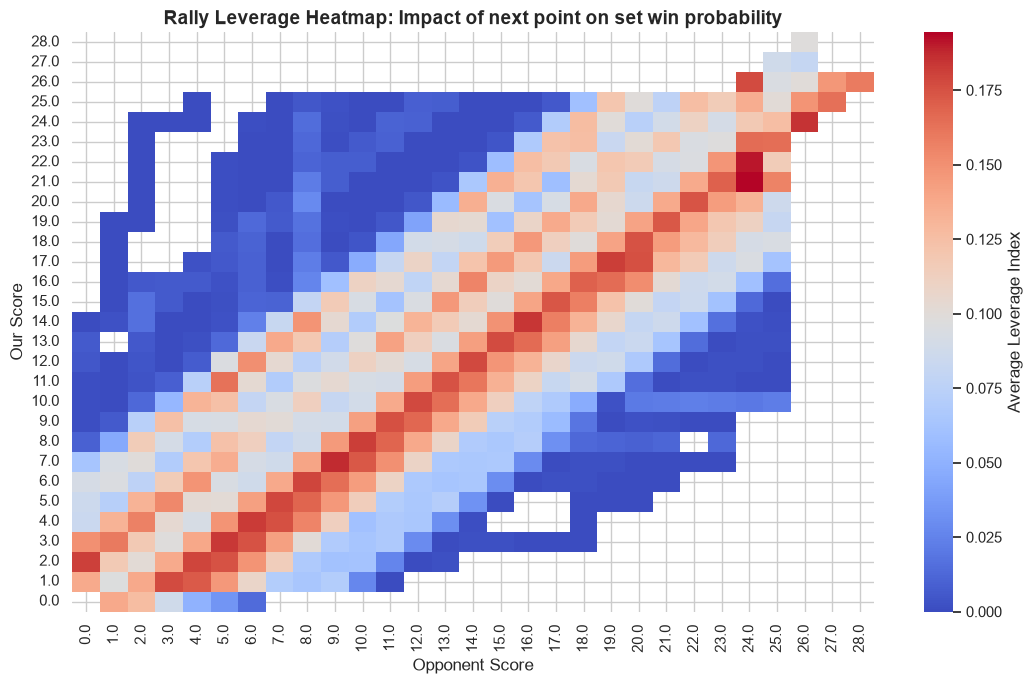

In [17]:
## Rally leverage index and timeout analysis
##P(Win Set | Win Upcoming Point): Your odds of winning the set if you win the next point.
##P(Win Set | Lose Upcoming Point): Your odds of winning the set if you lose the next point.
## Leverage Index: The gap between those two numbers:

# compute state swings for leverage
X_win = X.copy()
X_win['Us_Score'] += 1
X_win['Score_Diff'] += 1

X_lose = X.copy()
X_lose['Them_Score'] += 1
X_lose['Score_Diff'] -= 1

# P(win set | win point) vs P(win set | lose point)
P_win_if_win = xgb_set.predict_proba(X_win)[:, 1]
P_win_if_lose = xgb_set.predict_proba(X_lose)[:, 1]

# leverage = absolute difference between the two probabilities
model_df['Leverage_Index'] = np.abs(P_win_if_win - P_win_if_lose)

# compare TO timing vs average leverage index
timeout_leverage = model_df[model_df['Timeout_called'] == 1]['Leverage_Index'].mean()
overall_leverage = model_df['Leverage_Index'].mean()

print("=== Leverage Index Analysis===")
print(f"Average Rally Leverage Index: {overall_leverage:.4f}")
print(f"Average Leverage Index at Timeout Calls: {timeout_leverage:.4f}")

# Plot leverage heatmap across score states
plt.figure(figsize=(11, 7))
pivot_leverage = model_df.pivot_table(index='Us_Score', columns='Them_Score', values='Leverage_Index', aggfunc='mean')

sns.heatmap(pivot_leverage, cmap='coolwarm', annot=False, 
             cbar_kws={'label': 'Average Leverage Index'})
plt.title('Rally Leverage Heatmap: Impact of next point on set win probability', fontsize=14, fontweight='bold')
plt.xlabel('Opponent Score', fontsize=12)
plt.ylabel('Our Score', fontsize=12)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Conclusion for Q1
**Baseline vs. Timeout Leverage**: The average rally leverage index is **0.1008**, while the average leverage index at timeout calls is **0.1011**—showing virtually no difference between a routine rally and a timeout rally.

**"Leverage-Blind" Timeout Execution**: Timeouts are currently being called reactively (e.g., following an opponent point run) regardless of whether the match state is low-leverage (early sets) or high-leverage (late, close sets).

**Reframing Timeout Effectiveness**: Previous findings suggesting timeouts don't impact match outcomes occur because timeouts are frequently spent on low-stakes points where winning the point barely alters set-win probability.

Targeting High-Leverage Swings: Leverage spikes dramatically past point 20 in tight sets (score differential $\le 2$), reaching values above 0.20+ where winning a single point creates a massive swing in set-win odds.

**Actionable Coaching Strategy**: Establish a disciplined threshold to **reserve timeouts for high-leverage situations** (20+ score states in close sets) to maximize tactical impact.

# Start Goal 2:  Rotation & Lineup 
In volleyball, raw side-out and break-point percentages for a single rotation can fluctuate wildly due to small sample sizes or specific opponents. **Empirical Bayes Partial Pooling (Beta-Binomial model)** smooths out sample noise by shrinking small-sample rotation stats toward the overall team average, providing reliable estimates and **95% Bayesian Credible Intervals**.

Pooled Rate Calculation: The new smoothed win rate is calculated as: $$\text{Bayesian Rate} = \frac{\text{Posterior } \alpha}{\text{Posterior } \alpha + \text{Posterior } \beta}$$

If a rotation has a small sample size, its rate gets shrunk toward the overall team mean. If it has a large sample size, its rate stays close to its raw observed percentage.

In [20]:
#load data and filter
df = pd.read_csv('cleaned_volleyball_season_data-v2.csv')
rallies = df[df['Stage'].isin(['serve', 'receive']) & df['Rotation'].isin([1, 2, 3, 4, 5, 6])].copy()
rallies['Rotation'] = rallies['Rotation'].astype(int)
rallies['Point_Won'] = (rallies['Point_Winner'] == 'us').astype(int)

# Bayesian shrinkage for rotation win rates
def compute_bayesian_rates(stage_name):
    stage_df = rallies[rallies['Stage'] == stage_name].copy()

    # estimate varaince across match/season contexts
    subgroups = stage_df.groupby(['Season', 'Opponent', 'Set', 'Rotation'])['Point_Won'].agg(['count', 'sum', 'mean']).reset_index()
    p_bar = stage_df['Point_Won'].mean()
    var_p = subgroups['mean'].var()

    # fit beta prior hyperparameters (alpha, beta) using method of moments
    common_factor = (p_bar * (1 - p_bar) / max(var_p, 1e-5)) - 1
    alpha_0 = max(1.0, p_bar * common_factor)
    beta_0 = max(1.0, (1 - p_bar) * common_factor)

    # posterior beta(alpha_0 +wins, beta_0 + losses)
    rot_summary = stage_df.groupby('Rotation')['Point_Won'].agg(Attempts='count', Wins='sum', Raw_Rate='mean').reset_index()

    rot_summary['Posterior_Alpha'] = alpha_0 + rot_summary['Wins']
    rot_summary['Posterior_Beta'] = beta_0 + (rot_summary['Attempts'] - rot_summary['Wins'])
    rot_summary['Rate'] = rot_summary['Posterior_Alpha'] / (rot_summary['Posterior_Alpha'] + rot_summary['Posterior_Beta'])

    rot_summary['Raw_Pct'] = (rot_summary['Raw_Rate'] * 100).round(2)
    rot_summary['Bayesian_Pct'] = (rot_summary['Rate'] * 100).round(2)
    rot_summary['CI_Lower'] = (beta.ppf(0.025, rot_summary['Posterior_Alpha'], rot_summary['Posterior_Beta']) * 100).round(2)
    rot_summary['CI_Upper'] = (beta.ppf(0.975, rot_summary['Posterior_Alpha'], rot_summary['Posterior_Beta']) * 100).round(2)

    return rot_summary

so_bayesian = compute_bayesian_rates('receive')
bp_bayesian = compute_bayesian_rates('serve')

print("Bayesian Partial Pooling Model Fitted Successfully!")

Bayesian Partial Pooling Model Fitted Successfully!


In [21]:
# Compute rotation evaluation table
rot_eval = pd.DataFrame({
    'Rotation': so_bayesian['Rotation'], 
    'Sideout_Attempts': so_bayesian['Attempts'], 
    'Sideout_Pct': so_bayesian['Bayesian_Pct'], 
    'Sideout_95CI': [f"{l:.1f}% - {u:.1f}%" for l, u in zip(so_bayesian['CI_Lower'], so_bayesian['CI_Upper'])], 
    'Break_Attempts': bp_bayesian['Attempts'], 
    'Break_Pct': bp_bayesian['Bayesian_Pct'], 
    'Break_95CI': [f"{l:.1f}% - {u:.1f}%" for l, u in zip(bp_bayesian['CI_Lower'], bp_bayesian['CI_Upper'])], 
    'Net_Efficiency': (so_bayesian['Bayesian_Pct'] + bp_bayesian['Bayesian_Pct'] - 100).round(2)
}).sort_values(by='Net_Efficiency', ascending=False)

print("=== Rotation Evaluation Table ===")
display(rot_eval)

=== Rotation Evaluation Table ===


,Rotation,Sideout_Attempts,Sideout_Pct,Sideout_95CI,Break_Attempts,Break_Pct,Break_95CI,Net_Efficiency
5,6,353,48.17,43.0% - 53.4%,433,58.17,53.5% - 62.8%,6.34
0,1,408,50.73,45.9% - 55.6%,419,55.59,50.8% - 60.3%,6.32
2,3,517,47.01,42.7% - 51.3%,597,57.77,53.8% - 61.7%,4.78
3,4,432,50.46,45.8% - 55.1%,511,54.01,49.7% - 58.3%,4.47
1,2,561,47.07,43.0% - 51.2%,541,57.10,52.9% - 61.2%,4.17
4,5,415,46.52,41.8% - 51.3%,477,56.38,51.9% - 60.8%,2.90


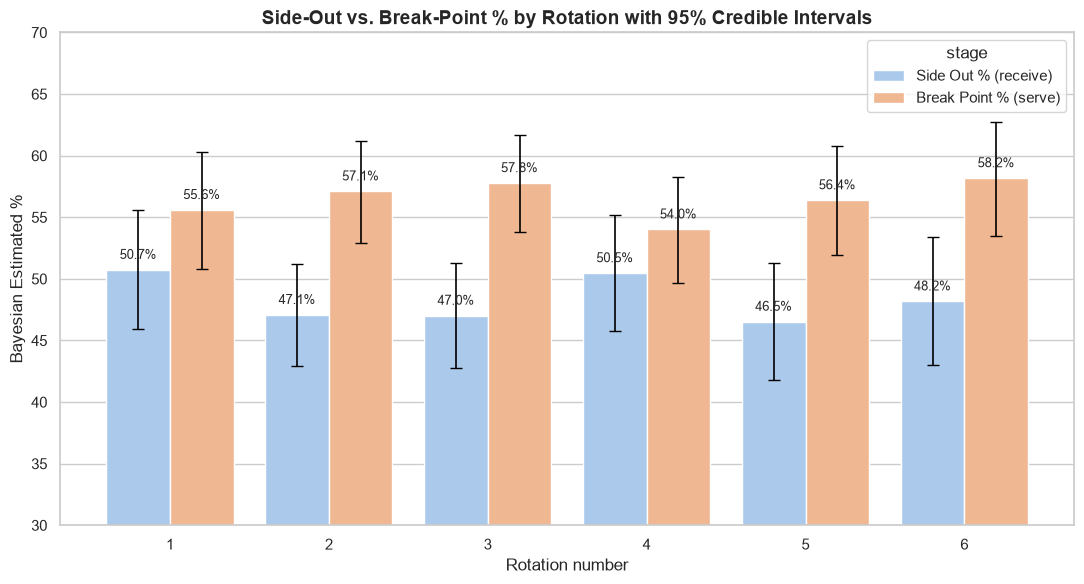

In [22]:
#Visualization — Side-Out vs. Break-Point % with 95% Credible Intervals

#reshape data for plotting
plot_df = pd.DataFrame({
    'Rotation': np.tile(np.arange(1, 7), 2),
    'stage': np.repeat(['Side Out % (receive)', 'Break Point % (serve)'], 6),
    'Pct': np.concatenate([so_bayesian['Bayesian_Pct'], bp_bayesian['Bayesian_Pct']]),
    'Err_Low': np.concatenate([so_bayesian['Bayesian_Pct'] - so_bayesian['CI_Lower'], bp_bayesian['Bayesian_Pct'] - bp_bayesian['CI_Lower']]),
    'Err_High': np.concatenate([so_bayesian['CI_Upper'] - so_bayesian['Bayesian_Pct'], bp_bayesian['CI_Upper'] - bp_bayesian['Bayesian_Pct']])
})

plt.figure(figsize=(11, 6))
ax = sns.barplot(data = plot_df, x='Rotation', y= 'Pct', hue='stage', palette='pastel')
plt.title('Side-Out vs. Break-Point % by Rotation with 95% Credible Intervals', fontsize=14, fontweight='bold')
plt.xlabel('Rotation number', fontsize=12)
plt.ylabel('Bayesian Estimated %', fontsize=12)
plt.ylim(30, 70)

# add error bars for 95% credible intervals
x_coords = [p.get_x() + p.get_width() / 2. for p in ax.patches if p.get_height() > 0]
y_vals = plot_df['Pct'].values
y_err_low = plot_df['Err_Low'].values
y_err_high = plot_df['Err_High'].values

for x, y, el, eh in zip(x_coords, y_vals, y_err_low, y_err_high):
     ax.errorbar(x, y, yerr=[[el], [eh]], fmt='none', c='black', capsize=4,
                 elinewidth=1.2) 
     ax.annotate(f"{y:.1f}%", (x, y), ha='center', va='bottom', xytext=(0, 6),
                 textcoords='offset points', fontsize=9) 
                        
plt.tight_layout() 
plt.show()

**Top Net Efficiency Rotations**: **Rotation 6** (+6.34% net) and **Rotation 1** (+6.32% net) are your team's most effective overall rotation states.

**Side-Out Bottlenecks**: **Rotation 5** is your weakest side-out rotation (**46.53%** side-out rate), followed by Rotation 3 (47.02%).

**Lineup &amp; Tactical Adjustments**: Because Rotation 5 has the lowest overall net efficiency (+2.93%), coaches should evaluate passing formations or hitter matchups when stuck in Rotation 5 on receive.

## Goal 3: Serve Strategy as risk-reward

This analysis evaluates each server's net expected point contribution (EV), clusters players into tactical profiles using K-Means, and tests how server error rates and efficiency change under pressure across score states.

$$\text{EV per Serve} = \frac{\text{Points Won on Serve} - \text{Points Lost on Serve}}{\text{Total Serves}}$$

In [25]:
# load data
df = pd.read_csv('cleaned_volleyball_season_data-v2.csv')
our_serves = df[(df['Stage'] == 'serve') & (df['Player_Name'] != 'Opponent')].copy()

# aggregate per server metrics
server_stats = our_serves.groupby('Player_Name').agg(
    Total_Serves=('Rally', 'count'),
    Aces=('Action', lambda x: (x == 'Ace').sum()),
    Errors=('Action', lambda x: (x.isin(['Serve', 'Foot Fault', 'Net'])).sum()),
    Points_Won=('Point_Winner', lambda x: (x == 'us').sum())
).reset_index()

# filter for servers with at least 40 attempts for stat reliability
server_stats = server_stats[server_stats['Total_Serves'] >= 40].copy()

# calculate % and Expected value (EV)
server_stats['Ace_Pct'] = (server_stats['Aces'] / server_stats['Total_Serves'] * 100)
server_stats['Error_Pct'] = (server_stats['Errors'] / server_stats['Total_Serves'] * 100)
server_stats['In_Play_Pct'] = 100 - server_stats['Ace_Pct'] - server_stats['Error_Pct']
server_stats['Break_Pct'] = (server_stats['Points_Won'] / server_stats['Total_Serves'] * 100)

# net ev per serve attempt (-1 to 1 scale)
server_stats['EV_per_Serve'] = (
    server_stats['Points_Won'] - (server_stats['Total_Serves'] - server_stats['Points_Won'])) / server_stats['Total_Serves']

# display sorted EV table
print("=== INDIVIDUAL SERVER EXPECTED VALUE (EV) TABLE ===")
display(server_stats.sort_values(by='EV_per_Serve', ascending=False).round(2))

=== INDIVIDUAL SERVER EXPECTED VALUE (EV) TABLE ===


,Player_Name,Total_Serves,Aces,Errors,Points_Won,Ace_Pct,Error_Pct,In_Play_Pct,Break_Pct,EV_per_Serve
5,Angie,95,16,11,69,16.84,11.58,71.58,72.63,0.45
14,Hrishika,264,96,50,171,36.36,18.94,44.70,64.77,0.30
8,Aom,420,129,86,270,30.71,20.48,48.81,64.29,0.29
3,Amie,130,75,34,82,57.69,26.15,16.15,63.08,0.26
1,Alisa,128,55,16,80,42.97,12.50,44.53,62.50,0.25
20,Pleng,207,67,53,127,32.37,25.60,42.03,61.35,0.23
22,Rin,140,52,38,85,37.14,27.14,35.71,60.71,0.21
9,Aranee,134,76,37,79,56.72,27.61,15.67,58.96,0.18
23,Yebin,82,31,15,47,37.80,18.29,43.90,57.32,0.15
12,Gabeen,70,33,20,39,47.14,28.57,24.29,55.71,0.11


d:\Anaconda\envs\volleyball_analysis\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


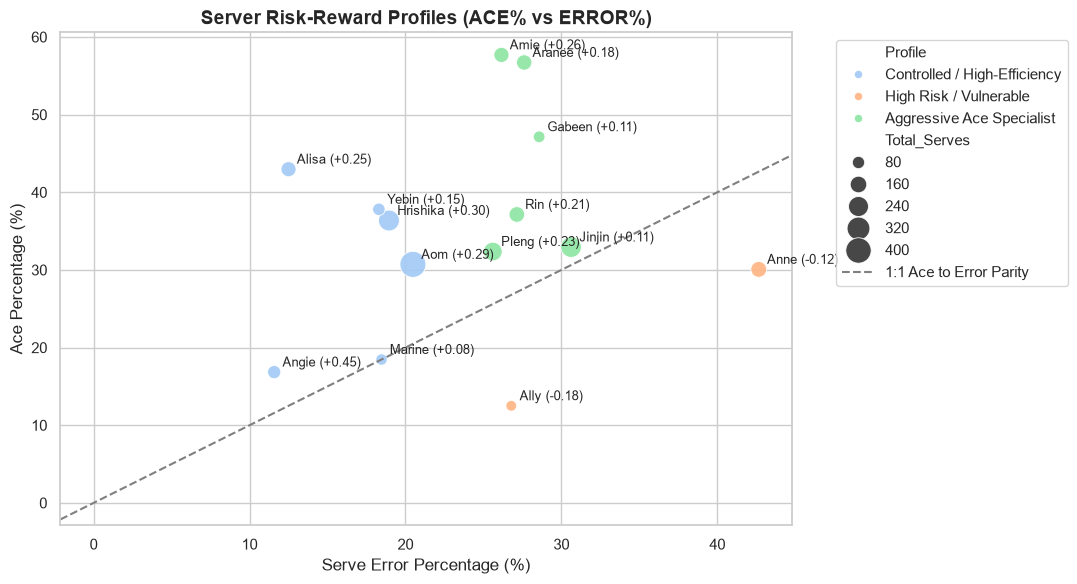

In [36]:
#K-means server profiling and risk reward chart

# Feature scaling for clustering
X = server_stats[['Ace_Pct', 'Error_Pct', 'Break_Pct']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-means clustering (3 profiles)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
server_stats['Cluster'] = kmeans.fit_predict(X_scaled)

#map cluster based on mean EV and error rate
cluster_summary = server_stats.groupby('Cluster')[['Ace_Pct', 'Error_Pct', 'Break_Pct', 'EV_per_Serve']].mean()
high_ev_cluster = cluster_summary['EV_per_Serve'].idxmax()
low_ev_cluster = cluster_summary['EV_per_Serve'].idxmin()

cluster_names = {}
for c in range (3):
    if c == high_ev_cluster:
        cluster_names[c] = 'Controlled / High-Efficiency'
    elif c == low_ev_cluster:
        cluster_names[c] = 'High Risk / Vulnerable'
    else:
        cluster_names[c] = 'Aggressive Ace Specialist'

server_stats['Profile'] = server_stats['Cluster'].map(cluster_names)

# scatter plot: ace % vs error %
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=server_stats,
    x='Error_Pct',
    y='Ace_Pct',
    hue='Profile',
    size='Total_Serves',
    sizes=(60, 350),
    palette='pastel',
    alpha=0.9
)

# annotate each server w player name and ev
for idx, row in server_stats.iterrows():
    plt.annotate(
        f"{row['Player_Name']} ({row['EV_per_Serve']:+.2f})",
        (row['Error_Pct'], row['Ace_Pct']),
        xytext=(6,4), textcoords='offset points',
        fontsize=9
    )

plt.axline((0,0), slope=1, color='gray', linestyle='--', label='1:1 Ace to Error Parity')
plt.title('Server Risk-Reward Profiles (ACE% vs ERROR%)', fontsize=14, fontweight='bold')
plt.xlabel('Serve Error Percentage (%)', fontsize=12) 
plt.ylabel('Ace Percentage (%)', fontsize=12) 
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 
plt.tight_layout()
plt.show()

=== SITUATIONAL SERVE PERFORMANCE BY SCORE STATE ===


,Score_State,Serves,Ace_Pct,Error_Pct,Break_Pct,EV_per_Serve
0,Close / Tied (|Diff| <= 1),611,29.79,33.06,47.95,-0.04
1,Leading (Us >= Them + 2),1303,41.75,17.11,69.92,0.40
2,Trailing (Us <= Them - 2),429,23.31,37.53,40.79,-0.18


C:\Users\Thitirat\AppData\Local\Temp\ipykernel_1816\228709385.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_perf, x='Score_State', y='Error_Pct', palette='pastel')


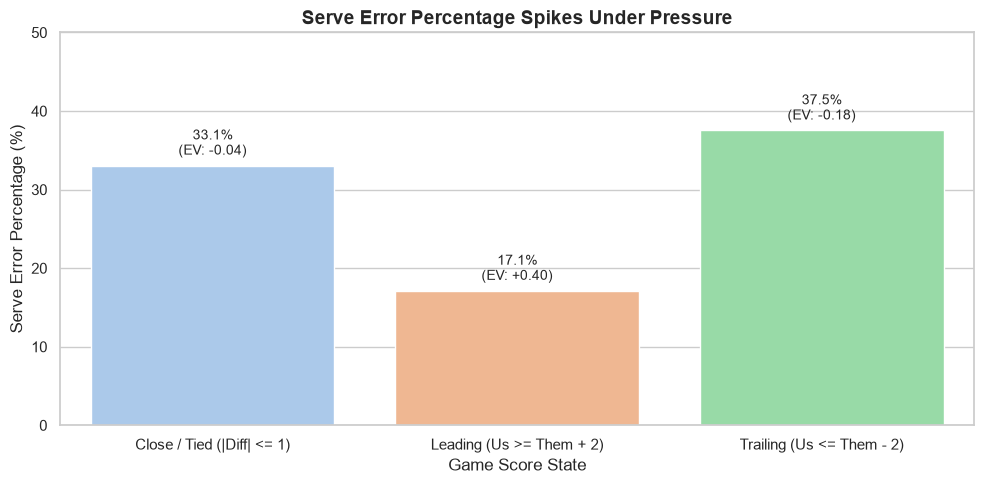

In [38]:
#Situational Serve Strategy (Score Context & Pressure Testing)

# Categorize score states
def categorize_score_state(row):
    diff = row['Us_Score'] - row['Them_Score']

    if diff <= -2:
        return 'Trailing (Us <= Them - 2)'
    elif abs(diff) <= 1:
        return 'Close / Tied (|Diff| <= 1)'
    else:
        return 'Leading (Us >= Them + 2)'

our_serves['Score_State'] = our_serves.apply(categorize_score_state, axis=1)

# evaluate performance by score state
state_perf = our_serves.groupby('Score_State').agg( Serves=('Rally', 'count'), Aces=('Action', lambda x: (x == 'Ace').sum()), Errors=('Action', lambda x: (x.isin(['Serve', 'Foot Fault', 'Net'])).sum()), Points_Won=('Point_Winner', lambda x: (x == 'us').sum()) ).reset_index()

state_perf['Ace_Pct'] = (state_perf['Aces'] / state_perf['Serves']) * 100
state_perf['Error_Pct'] = (state_perf['Errors'] / state_perf['Serves']) * 100 
state_perf['Break_Pct'] = (state_perf['Points_Won'] / state_perf['Serves']) * 100 
state_perf['EV_per_Serve'] = ( state_perf['Points_Won'] - (state_perf['Serves'] - state_perf['Points_Won']) ) / state_perf['Serves']

print("=== SITUATIONAL SERVE PERFORMANCE BY SCORE STATE ===") 
display(state_perf[['Score_State', 'Serves', 'Ace_Pct', 'Error_Pct', 'Break_Pct', 'EV_per_Serve']].round(2))

# bar chart
plt.figure(figsize=(10, 5)) 
sns.barplot(data=state_perf, x='Score_State', y='Error_Pct', palette='pastel') 
plt.title('Serve Error Percentage Spikes Under Pressure', fontsize=14, fontweight='bold') 
plt.xlabel('Game Score State', fontsize=12) 
plt.ylabel('Serve Error Percentage (%)', fontsize=12)

for i, row in state_perf.iterrows(): 
    plt.annotate(f"{row['Error_Pct']:.1f}%\n(EV: {row['EV_per_Serve']:+.2f})", (i, row['Error_Pct']), ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontsize=10) 

plt.ylim(0, 50) 
plt.tight_layout() 
plt.show()